# 05 · DBSCAN vs K-Means

Both algorithms are now re-run on **identical feature matrices**, with identical
evaluation code. All numbers below come from these runs.

Two comparisons are reported:

1. **Geographic space (2-D)** — the hotspot question.
2. **Combined space (11-D)** — geography *and* housing characteristics.

Silhouette is calculated on a reproducible 8,000-point sample and excludes
DBSCAN noise points; coverage (noise %) is therefore reported alongside it.

In [1]:
%matplotlib inline

import os
import sys
from pathlib import Path

# Avoid a noisy joblib CPU-detection warning on Windows.
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the project root (the folder that contains src/) so the notebooks run
# whether Jupyter was started from notebooks/ or from the project root.
ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import preprocessing as pp
import clustering as cl
import visualization as viz

viz.set_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)

print("Project root:", ROOT)
print("Dataset:", pp.DATA_PATH)

Project root: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering
Dataset: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\data\housing.csv


In [2]:
import time
from sklearn.datasets import make_moons
from sklearn.metrics import adjusted_rand_score

ds_geo = pp.prepare_dataset("geo")
ds_combined = pp.prepare_dataset("geo_housing")

EPS_GEO, MS_GEO = 0.06, 30
EPS_COMB, MS_COMB = 1.6, 5
K_GEO = 6
K_COMB = 5

## 1. Re-run all four configurations

In [3]:
def time_dbscan(X, eps, min_samples):
    start = time.perf_counter()
    labels = cl.run_dbscan(X, eps=eps, min_samples=min_samples)
    return labels, time.perf_counter() - start


def time_kmeans(X, k):
    start = time.perf_counter()
    model = cl.run_kmeans(X, k)
    return model.labels_, time.perf_counter() - start


runs = {
    "DBSCAN (geo)":    (ds_geo, *time_dbscan(ds_geo.X, EPS_GEO, MS_GEO)),
    "K-Means (geo)":   (ds_geo, *time_kmeans(ds_geo.X, K_GEO)),
    "DBSCAN (11-D)":   (ds_combined, *time_dbscan(ds_combined.X, EPS_COMB, MS_COMB)),
    "K-Means (11-D)":  (ds_combined, *time_kmeans(ds_combined.X, K_COMB)),
}

rows = {}
for name, (dataset, labels, runtime) in runs.items():
    metrics = cl.evaluate_clustering(dataset.X, labels, sample_size=8000)
    metrics["runtime_s"] = round(runtime, 3)
    rows[name] = metrics
    print(f"{name:15s} clusters={metrics['n_clusters']:3d} "
          f"noise={metrics['noise_pct']:5.2f}% "
          f"silhouette={metrics['silhouette']:.3f} "
          f"runtime={runtime:.2f}s")

all_results = pd.DataFrame(rows).T
all_results.to_csv(pp.OUTPUT_DIR / "algorithm_results.csv")
all_results.round(3)

DBSCAN (geo)    clusters= 22 noise= 6.07% silhouette=0.377 runtime=0.27s


K-Means (geo)   clusters=  6 noise= 0.00% silhouette=0.570 runtime=0.11s


DBSCAN (11-D)   clusters=  3 noise= 1.31% silhouette=0.642 runtime=5.26s


K-Means (11-D)  clusters=  5 noise= 0.00% silhouette=0.214 runtime=0.11s


,n_clusters,n_noise,noise_pct,n_clustered_points,silhouette,davies_bouldin,calinski_harabasz,silhouette_sample_size,runtime_s
DBSCAN (geo),22.0,1252.0,6.07,19388.0,0.377,0.495,39605.023,8000.0,0.272
K-Means (geo),6.0,0.0,0.00,20640.0,0.570,0.689,87008.189,8000.0,0.109
DBSCAN (11-D),3.0,270.0,1.31,20370.0,0.642,0.370,147.885,8000.0,5.262
K-Means (11-D),5.0,0.0,0.00,20640.0,0.214,1.297,4754.937,8000.0,0.107


## 2. Side-by-side comparison on the same feature space

### Geographic space (2-D)

In [4]:
comparison_geo = cl.comparison_table({
    "DBSCAN": rows["DBSCAN (geo)"],
    "K-Means": rows["K-Means (geo)"],
})
comparison_geo.to_csv(pp.OUTPUT_DIR / "comparison_geo.csv")
comparison_geo.round(3)

,n_clusters,n_noise,noise_pct,silhouette,davies_bouldin,calinski_harabasz,runtime_s
algorithm,,,,,,,
DBSCAN,22,1252,6.07,0.377,0.495,39605.023,0.272
K-Means,6,0,0.00,0.570,0.689,87008.189,0.109


saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\algorithm_comparison_geo.png


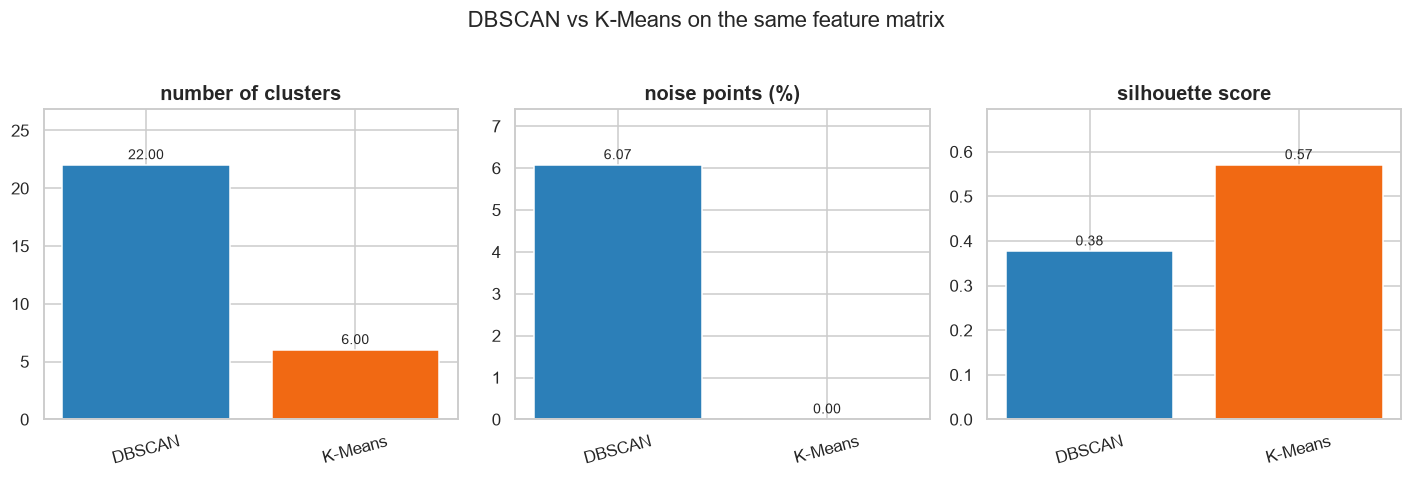

saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\dbscan_vs_kmeans_geo.png


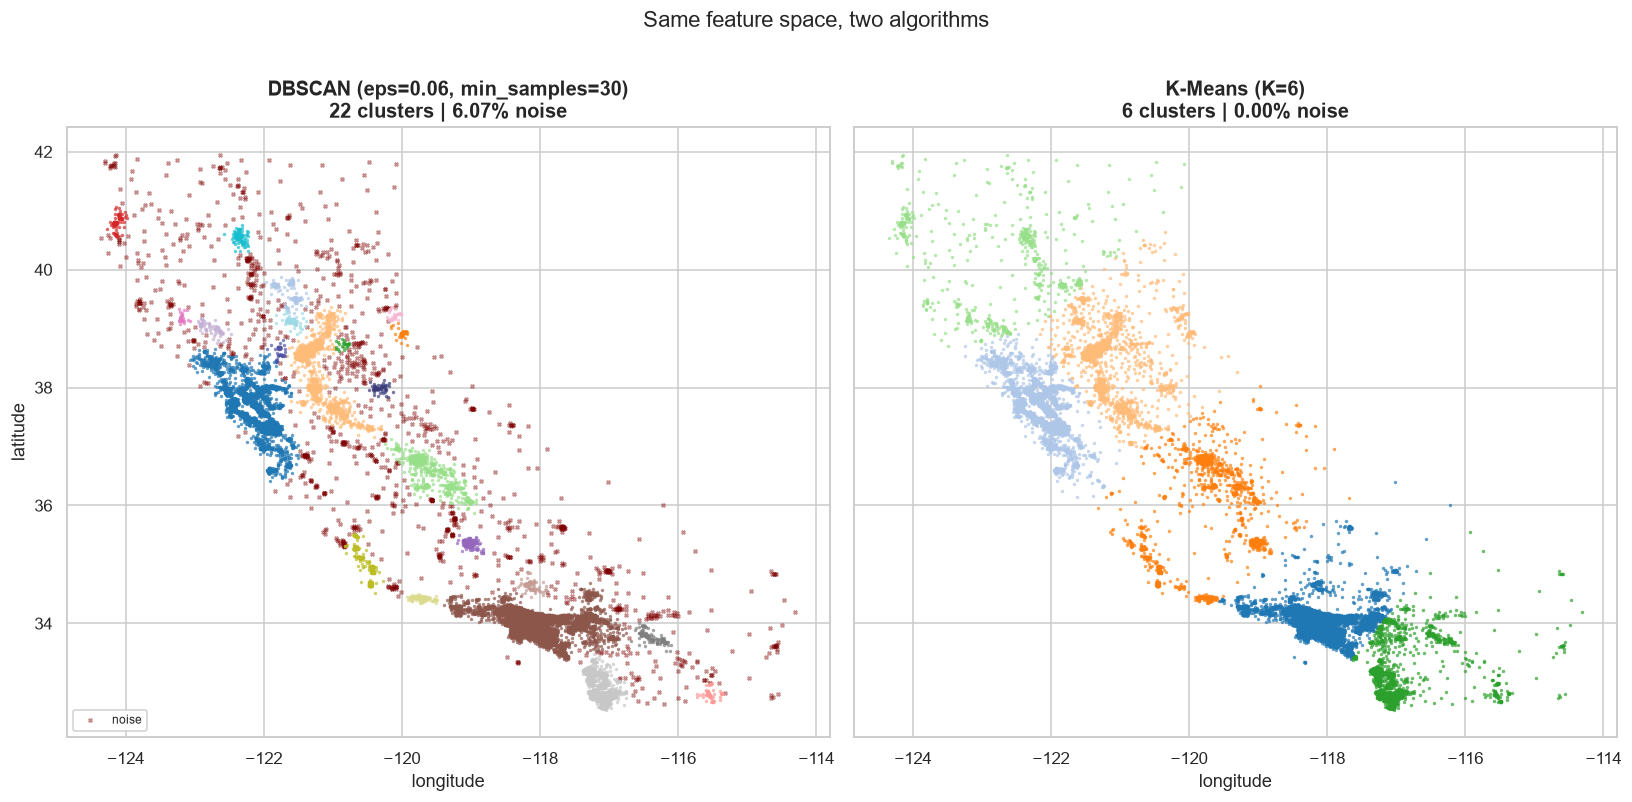

In [5]:
fig, path = viz.plot_comparison_bars(comparison_geo, name="algorithm_comparison_geo")
print("saved:", path)
plt.show()

labels_db_geo = runs["DBSCAN (geo)"][1]
labels_km_geo = runs["K-Means (geo)"][1]

fig, path = viz.plot_side_by_side_maps(
    ds_geo.df, labels_db_geo, labels_km_geo,
    title_a="DBSCAN (eps=0.06, min_samples=30)",
    title_b="K-Means (K=6)",
    name="dbscan_vs_kmeans_geo",
)
print("saved:", path)
plt.show()

In [6]:
profile_db_geo = cl.cluster_profile(ds_geo.df, labels_db_geo)
profile_km_geo = cl.cluster_profile(ds_geo.df, labels_km_geo)

print(viz.save_plotly_bar(
    profile_db_geo,
    filename="dbscan_avg_value_interactive.html",
    title="DBSCAN: average house value by cluster",
))
print(viz.save_plotly_bar(
    profile_km_geo,
    filename="kmeans_avg_value_interactive.html",
    title="K-Means: average house value by cluster",
))


D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\dbscan_avg_value_interactive.html
D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\kmeans_avg_value_interactive.html


The difference is immediately visible: DBSCAN leaves a sparse scatter of dark-red
noise across the mountains and deserts, while K-Means paints the entire state
into six solid regions. DBSCAN's clusters hug dense urban corridors; K-Means
regions extend into empty land because every point must be assigned.

### Combined space (11-D)

In [7]:
comparison_combined = cl.comparison_table({
    "DBSCAN": rows["DBSCAN (11-D)"],
    "K-Means": rows["K-Means (11-D)"],
})
comparison_combined.to_csv(pp.OUTPUT_DIR / "comparison_combined.csv")
comparison_combined.round(3)

,n_clusters,n_noise,noise_pct,silhouette,davies_bouldin,calinski_harabasz,runtime_s
algorithm,,,,,,,
DBSCAN,3,270,1.31,0.642,0.370,147.885,5.262
K-Means,5,0,0.00,0.214,1.297,4754.937,0.107


saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\algorithm_comparison_combined.png


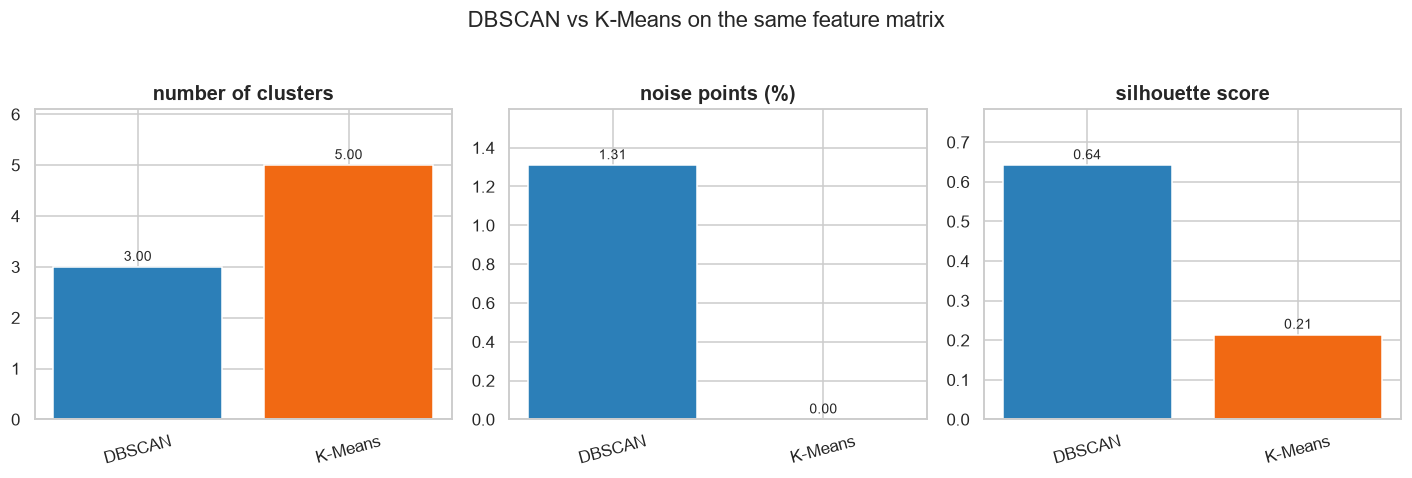

saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\dbscan_vs_kmeans_combined.png


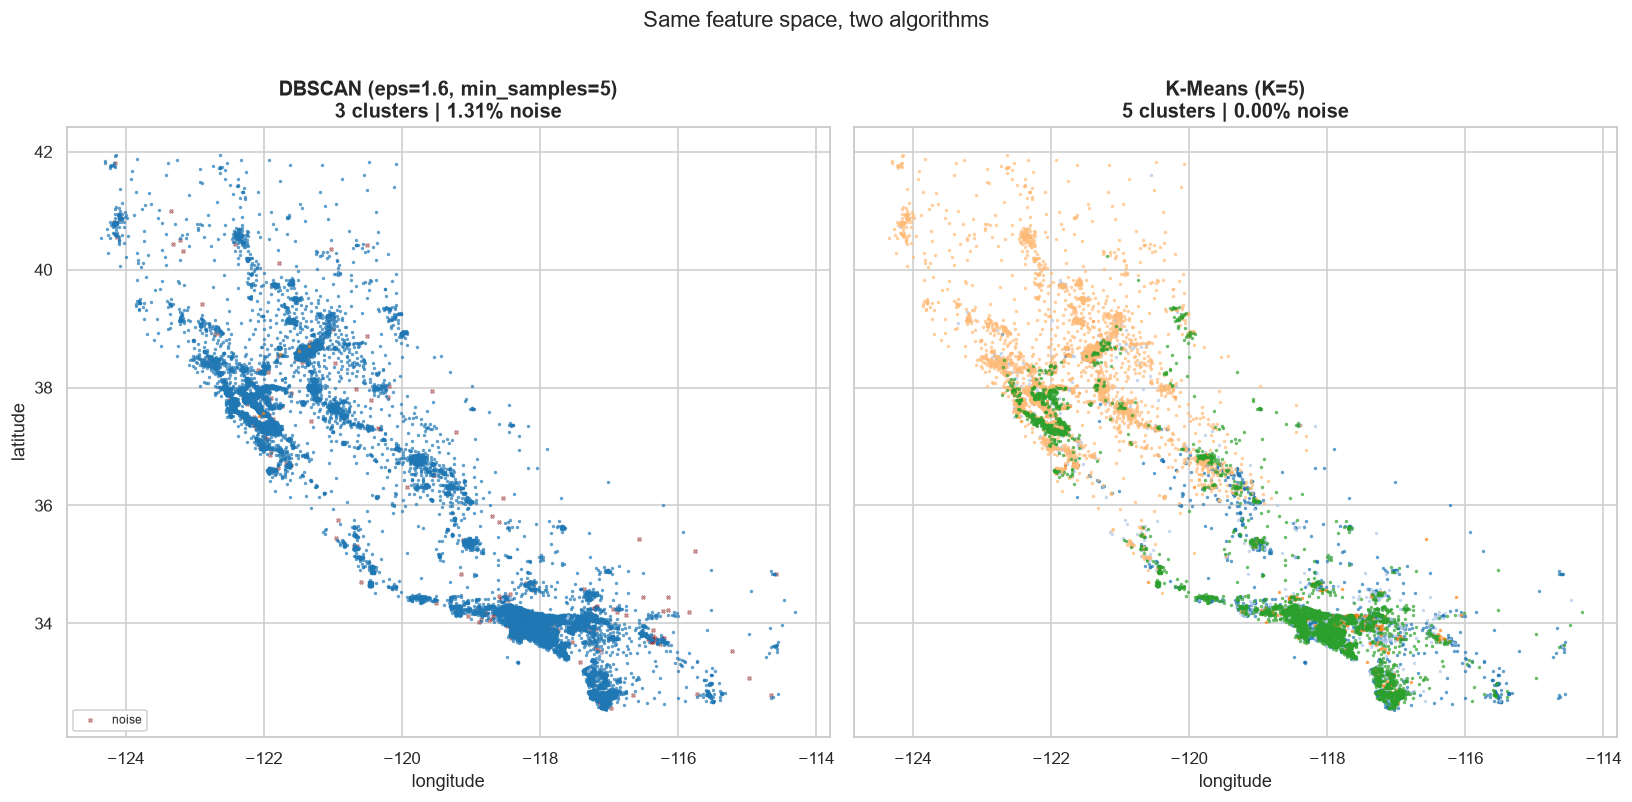

In [8]:
fig, path = viz.plot_comparison_bars(comparison_combined,
                                     name="algorithm_comparison_combined")
print("saved:", path)
plt.show()

fig, path = viz.plot_side_by_side_maps(
    ds_combined.df,
    runs["DBSCAN (11-D)"][1],
    runs["K-Means (11-D)"][1],
    title_a="DBSCAN (eps=1.6, min_samples=5)",
    title_b="K-Means (K=5)",
    name="dbscan_vs_kmeans_combined",
)
print("saved:", path)
plt.show()

In 11-D, DBSCAN's single dominant cluster (98.63% of rows) makes its silhouette
of **0.642** look excellent — a textbook example of why a metric must be read
together with the result. The two "extra" clusters contain only 13 points total.
K-Means gives a more usable partition there, although its silhouette is only
**0.214**.

## 3. Cluster-shape sensitivity (synthetic illustration)

This section uses **synthetic two-moons data** — not housing data — to isolate a
structural difference between the algorithms. Two interleaving crescents cannot
be separated by a straight Voronoi boundary. Adjusted Rand Index (ARI) measures
agreement with the known true labels (1.0 = perfect).

DBSCAN  ARI = 1.000  | clusters=2, noise=0.0%
K-Means ARI = 0.249  | clusters=2


saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\synthetic_shape_comparison.png


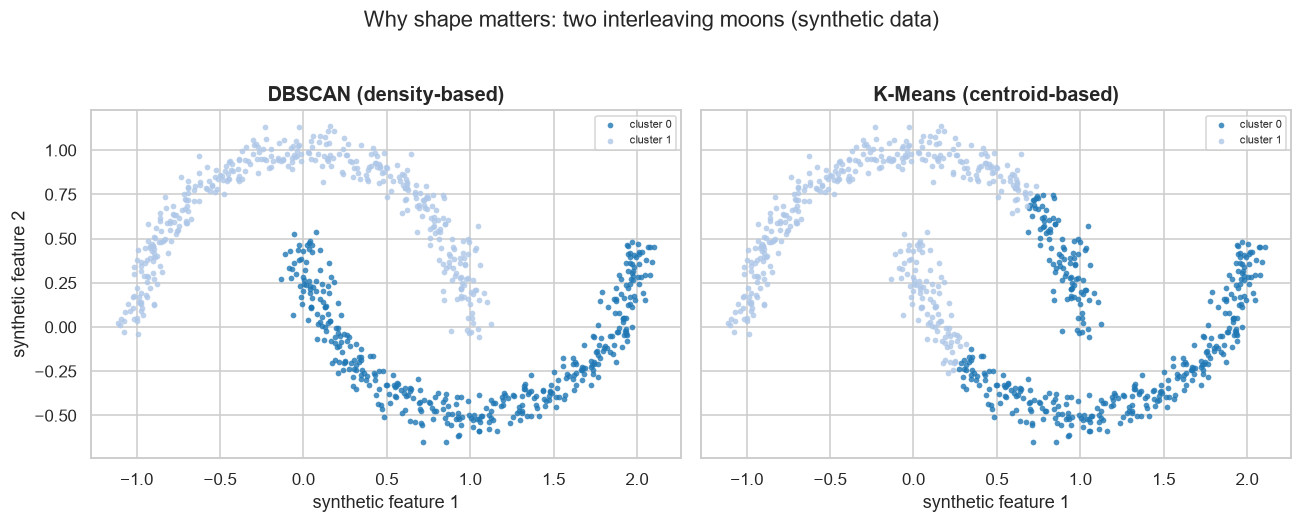

In [9]:
X_moons, y_moons = make_moons(n_samples=800, noise=0.06, random_state=42)

moons_db = cl.run_dbscan(X_moons, eps=0.2, min_samples=5)
moons_km = cl.run_kmeans(X_moons, 2).labels_

ari_db = adjusted_rand_score(y_moons, moons_db)
ari_km = adjusted_rand_score(y_moons, moons_km)

print(f"DBSCAN  ARI = {ari_db:.3f}  | clusters={len(set(moons_db)) - (1 if -1 in moons_db else 0)}, "
      f"noise={(moons_db == -1).mean() * 100:.1f}%")
print(f"K-Means ARI = {ari_km:.3f}  | clusters={len(set(moons_km))}")

fig, path = viz.plot_synthetic_shapes(X_moons, moons_db, moons_km)
print("saved:", path)
plt.show()

DBSCAN recovers the moons almost perfectly (ARI ≈ 1.00); K-Means slices across
both crescents (ARI ≈ 0.25). On the housing map, the same property appears as
DBSCAN's long connected coastal corridors versus K-Means' compact, roughly
circular regions.

## 4. Computational performance

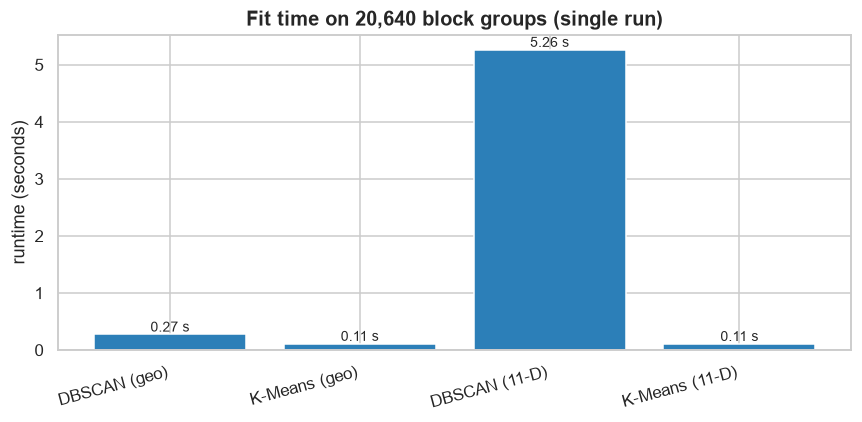

,algorithm,runtime_s,rows
0,DBSCAN (geo),0.272,20640
1,K-Means (geo),0.109,20640
2,DBSCAN (11-D),5.262,20640
3,K-Means (11-D),0.107,20640


In [10]:
runtime_table = pd.DataFrame({
    "algorithm": ["DBSCAN (geo)", "K-Means (geo)", "DBSCAN (11-D)", "K-Means (11-D)"],
    "runtime_s": [rows[name]["runtime_s"] for name in
                  ["DBSCAN (geo)", "K-Means (geo)", "DBSCAN (11-D)", "K-Means (11-D)"]],
})
runtime_table["rows"] = len(ds_geo.df)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(runtime_table["algorithm"], runtime_table["runtime_s"], color="#2c7fb8")
ax.bar_label(bars, fmt="%.2f s", fontsize=9)
ax.set_ylabel("runtime (seconds)")
ax.set_title("Fit time on 20,640 block groups (single run)")
plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
plt.tight_layout()
plt.show()

runtime_table

Timings are from single runs on the same machine and should be read as
indicative, not benchmark-grade. The pattern is clear: K-Means is the faster
algorithm (≈0.1–0.25 s), while DBSCAN costs more, especially in 11 dimensions
(**≈5–6 s**, roughly 30–40× slower than K-Means there). DBSCAN's cost comes from
neighbourhood queries over the full pairwise structure; K-Means does a fixed
number of centroid iterations.

## 5. Systematic comparison

| dimension | DBSCAN (geo) | K-Means (geo) | DBSCAN (11-D) | K-Means (11-D) |
|---|---|---|---|---|
| clusters | 22 (discovered) | 6 (chosen) | 3 (1 dominant) | 5 (chosen) |
| noise | 1,252 (6.07%) | 0 (by design) | 270 (1.31%) | 0 (by design) |
| silhouette | 0.377 (clustered only) | **0.570** (all points) | 0.642 (degenerate) | 0.214 |
| Davies–Bouldin (lower better) | 0.495 | 0.689 | **0.370** | 1.297 |
| Calinski–Harabasz (higher better) | 39,605 | **87,008** | 148 | **4,755** |
| runtime | ≈0.3 s | **≈0.1–0.25 s** | ≈5–6 s | **≈0.1–0.25 s** |
| noise detection | yes | no | yes | no |
| irregular shapes | yes (chained corridors) | no (convex regions) | n/a | no |
| parameter sensitivity | high (`eps`, `min_samples`) | moderate (`K`) | very high | moderate (`K`) |
| interpretability | hotspot cores + anomalies | complete regional map | poor (one mega-cluster) | attribute segments |

**Strengths and weaknesses**

- **DBSCAN** finds arbitrary-shaped dense areas, explicitly marks isolated
  locations, and does not require a cluster count. Its weaknesses are parameter
  sensitivity and a dramatic failure in high-dimensional space: with 9 attribute
  dimensions, 98.63% of the data collapses into one cluster.
- **K-Means** is fast, stable with a fixed seed, and always yields a complete,
  easy-to-report regional map. But it forces isolated ranches into urban
  clusters, imposes convex shapes, and still requires a sensible `K`; its
  silhouette optimum (K=2) is analytically useless.
- Neither is universally better. The choice depends on whether the question is
  "where are the dense hotspot cores?" (DBSCAN) or "give every block group a
  region label" (K-Means).

## 6. Final conclusions

**Where are the major housing hotspots?**  
Southern California/Los Angeles is the largest dense region (8,862 DBSCAN block
groups, 42.9% of the data; mean value \$230,501), followed by the San Francisco
Bay Area (4,749; \$264,124), San Diego (1,586; \$197,396) and Sacramento (1,696;
\$130,473). The Central Valley is dense but inexpensive (Fresno area: 815 block
groups, \$82,291; Bakersfield: 234, \$80,999).

**Do expensive properties form distinct geographical clusters?**  
Yes. In the K-Means regions, 14.0% of Bay Area block groups and 10.7% of Los
Angeles block groups are ≥ \$400k, versus 0.3% in Sacramento and 0.0% in the far
north (dataset-wide: 8.58%). The single most expensive DBSCAN cluster is the
Santa Barbara coast (162 block groups, mean \$330,037).

**Are clusters associated with higher median income?**  
Strongly. Mean income and mean house value correlate at **r ≈ 0.91** across the
22 DBSCAN clusters and **r ≈ 0.99** across the six K-Means regions. Every
high-value region is also a high-income region.

**How does DBSCAN distinguish dense areas from isolated locations?**  
Points that cannot reach 30 neighbours within `eps=0.06` become noise: 1,252
block groups (6.07%). Their mean value is \$110,920 and only 1.04% are ≥ \$400k,
so they are mostly remote low-density areas rather than luxury outliers.

**What does K-Means reveal that DBSCAN does not?**  
A complete, gap-free regional segmentation — including low-density areas that
DBSCAN discards — and, in the 11-D space, attribute-based segments such as the
high-income cluster (mean income 6.02, mean value \$290,047). It also shows how
much of California is "near-coastal but not expensive".

**Which algorithm is more suitable for housing hotspots here?**  
Use **DBSCAN on the geographic matrix** to define hotspot cores and flag
isolated locations, and **K-Means** when a complete regional label is needed for
dashboards or further modelling. Running DBSCAN directly on the 11-D
geo+housing matrix is not advisable without feature weighting, because density
is overwhelmed by the nine attribute dimensions.

**Limitations.** The data are 1990 census block groups, not individual
transactions; prices are top-coded at \$500,001; clusters are based on
Euclidean distance and ignore roads, coastline barriers and spatial
autocorrelation; and the usual caveat applies that a cluster is a description of
this dataset, not a causal claim about prices.

## Generated deliverables

**Static figures** (`outputs/visualizations/`): price distribution, feature
distributions, geography, correlation heatmap, k-distance graphs, DBSCAN grid
heatmaps, DBSCAN/K-Means cluster maps, average value by cluster, comparison bars,
and the synthetic shape comparison.

**Interactive Folium maps** (`outputs/maps/`): `housing_geography.html`,
`dbscan_clusters.html`, `dbscan_noise.html`, `kmeans_clusters.html`.

**Interactive Plotly charts** (`outputs/visualizations/`):
`price_distribution_interactive.html`, `dbscan_clusters_interactive.html`,
`kmeans_clusters_interactive.html`, `dbscan_clusters_scatter.html`,
`kmeans_clusters_scatter.html`, `dbscan_avg_value_interactive.html`,
`kmeans_avg_value_interactive.html`.

**Result tables** (`outputs/`): DBSCAN/K-Means grids, cluster profiles, labels,
and the two algorithm comparison tables.